In [0]:
from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt
catalog_name = spark.sql("SELECT current_catalog()").first()[0]
schema_name = spark.sql("SELECT current_schema()").first()[0]
PERFORMANCE_TABLE = f"{catalog_name}.{schema_name}.fraud_model_performance"
NORMAL_DRIFT_TABLE = f"{catalog_name}.{schema_name}.fraud_drift_normal"
SIMULATED_DRIFT_TABLE = f"{catalog_name}.{schema_name}.fraud_drift_simulated"
PREDICTIONS_TABLE = f"{catalog_name}.{schema_name}.fraud_predictions_test"
performance_df = spark.table(PERFORMANCE_TABLE)
normal_drift_df = spark.table(NORMAL_DRIFT_TABLE)
simulated_drift_df = spark.table(SIMULATED_DRIFT_TABLE)
predictions_df = spark.table(PREDICTIONS_TABLE)
print("Monitoring tables loaded.")

Monitoring tables loaded.


In [0]:
display(
   performance_df
   .orderBy("metric_name")
   .select("metric_name", "metric_value", "model_run_id", "measured_at_utc")
)

metric_name,metric_value,model_run_id,measured_at_utc
average_precision,0.7159122424484009,ec060bf2a1fb44d29c250a12965238ee,2026-10-11T09:44:01.454898+00:00
f1_score,0.11435832274459974,ec060bf2a1fb44d29c250a12965238ee,2026-10-11T09:44:01.454877+00:00
precision,0.06097560975609756,ec060bf2a1fb44d29c250a12965238ee,2026-10-11T09:44:01.454811+00:00
recall,0.9183673469387755,ec060bf2a1fb44d29c250a12965238ee,2026-10-11T09:44:01.454862+00:00
roc_auc,0.9721687370080279,ec060bf2a1fb44d29c250a12965238ee,2026-10-11T09:44:01.454888+00:00


In [0]:
drift_summary = pd.DataFrame([
   {
       "batch": "Normal test batch",
       "features_monitored": normal_drift_df.count(),
       "PSI alerts": normal_drift_df.filter(
           F.col("psi_alert") == True
       ).count(),
       "KS alerts": normal_drift_df.filter(
           F.col("ks_alert") == True
       ).count()
   },
   {
       "batch": "Simulated drift batch",
       "features_monitored": simulated_drift_df.count(),
       "PSI alerts": simulated_drift_df.filter(
           F.col("psi_alert") == True
       ).count(),
       "KS alerts": simulated_drift_df.filter(
           F.col("ks_alert") == True
       ).count()
   }
])
display(drift_summary)

batch,features_monitored,PSI alerts,KS alerts
Normal test batch,30,0,2
Simulated drift batch,30,0,4


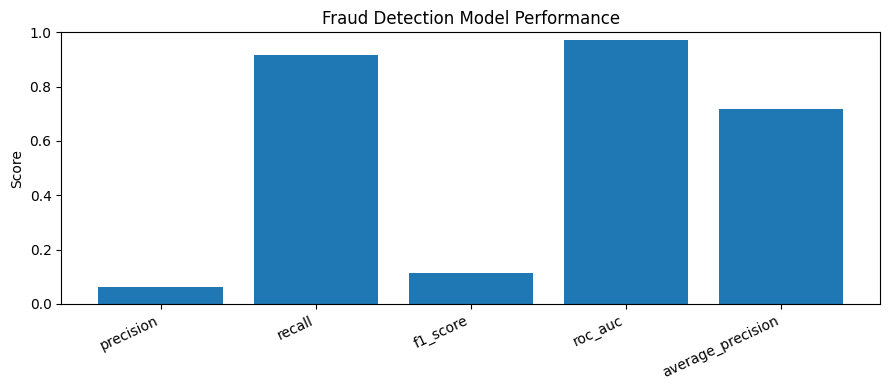

In [0]:
performance_pdf = performance_df.select(
   "metric_name", "metric_value"
).toPandas()
plt.figure(figsize=(9, 4))
plt.bar(
   performance_pdf["metric_name"],
   performance_pdf["metric_value"]
)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Fraud Detection Model Performance")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

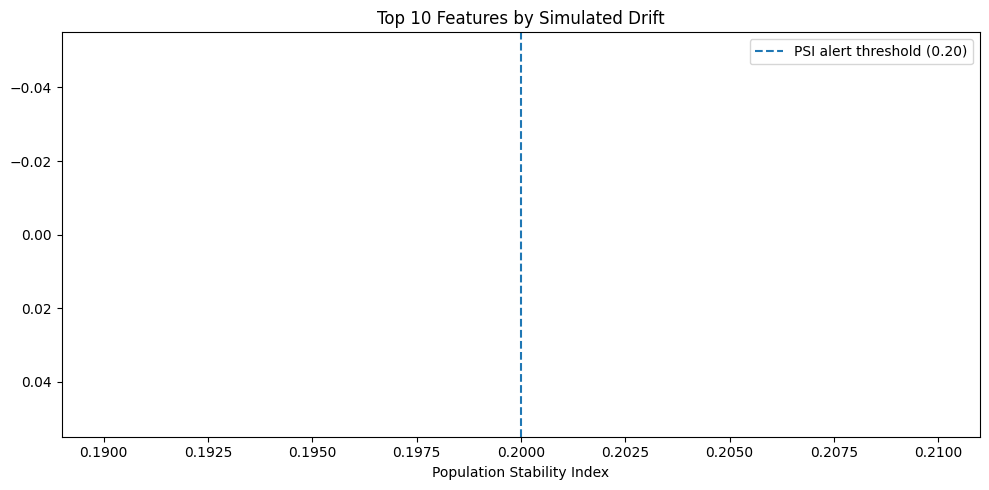

In [0]:
simulated_drift_pdf = simulated_drift_df.select(
   "feature", "psi", "psi_alert"
).toPandas().dropna(subset=["psi"])
top_drift = simulated_drift_pdf.sort_values(
   "psi", ascending=False
).head(10)
plt.figure(figsize=(10, 5))
plt.barh(top_drift["feature"], top_drift["psi"])
plt.axvline(
   0.20,
   linestyle="--",
   label="PSI alert threshold (0.20)"
)
plt.xlabel("Population Stability Index")
plt.title("Top 10 Features by Simulated Drift")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()

predicted_class,count
0,55486
1,1476


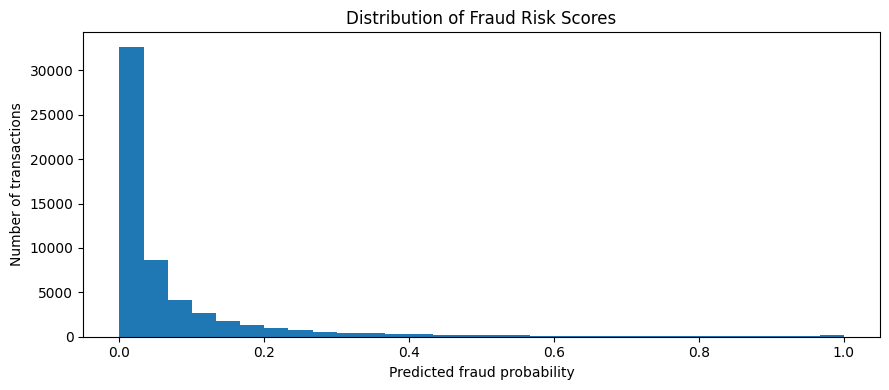

In [0]:
prediction_summary = (
   predictions_df
   .groupBy("predicted_class")
   .count()
   .orderBy("predicted_class")
)
display(prediction_summary)
probabilities_pdf = predictions_df.select(
   "fraud_probability"
).toPandas()
plt.figure(figsize=(9, 4))
plt.hist(
   probabilities_pdf["fraud_probability"],
   bins=30
)
plt.xlabel("Predicted fraud probability")
plt.ylabel("Number of transactions")
plt.title("Distribution of Fraud Risk Scores")
plt.tight_layout()
plt.show()

In [0]:
normal_psi_alerts = normal_drift_df.filter(
   F.col("psi_alert") == True
).count()
normal_ks_alerts = normal_drift_df.filter(
   F.col("ks_alert") == True
).count()
simulated_psi_alerts = simulated_drift_df.filter(
   F.col("psi_alert") == True
).count()
simulated_ks_alerts = simulated_drift_df.filter(
   F.col("ks_alert") == True
).count()
monitoring_status = pd.DataFrame([
   {
       "check": "Normal batch PSI alerts",
       "value": normal_psi_alerts,
       "status": "REVIEW" if normal_psi_alerts > 0 else "OK"
   },
   {
       "check": "Normal batch KS alerts",
       "value": normal_ks_alerts,
       "status": "REVIEW" if normal_ks_alerts > 0 else "OK"
   },
   {
       "check": "Simulated batch PSI alerts",
       "value": simulated_psi_alerts,
       "status": "DRIFT DETECTED" if simulated_psi_alerts > 0 else "CHECK MONITOR"
   },
   {
       "check": "Simulated batch KS alerts",
       "value": simulated_ks_alerts,
       "status": "DRIFT DETECTED" if simulated_ks_alerts > 0 else "CHECK MONITOR"
   }
])
display(monitoring_status)

check,value,status
Normal batch PSI alerts,0,OK
Normal batch KS alerts,2,REVIEW
Simulated batch PSI alerts,0,CHECK MONITOR
Simulated batch KS alerts,4,DRIFT DETECTED


In [0]:
from pyspark.sql import functions as F
EVENTS_TABLE = (
   f"{catalog_name}.{schema_name}.fraud_monitoring_events"
)
events_df = spark.table(EVENTS_TABLE)
# Show the most recent monitoring events
display(
   events_df
   .orderBy(F.desc("event_time_utc"))
   .select(
       "event_time_utc",
       "check_name",
       "status",
       "severity",
       "observed_value",
       "threshold_value",
       "message"
   )
)
# Summarize alert counts
display(
   events_df
   .groupBy("status", "severity")
   .count()
   .orderBy(F.desc("count"))
)

event_time_utc,check_name,status,severity,observed_value,threshold_value,message
2026-10-11T10:22:16.333495+00:00,performance:roc_auc,OK,INFO,0.9721687370080279,null,roc_auc recorded; no alert threshold configured
2026-10-11T10:22:16.333495+00:00,drift:Amount,OK,INFO,9.744413922173699E-5,0.2,No configured drift threshold exceeded for Amount
2026-10-11T10:22:16.333495+00:00,performance:f1_score,OK,INFO,0.11435832274459974,null,f1_score recorded; no alert threshold configured
2026-10-11T10:22:16.333495+00:00,drift:V20,OK,INFO,2.133751224351995E-5,0.2,No configured drift threshold exceeded for V20
2026-10-11T10:22:16.333495+00:00,drift:V24,OK,INFO,1.328756308094777E-4,0.2,No configured drift threshold exceeded for V24
2026-10-11T10:22:16.333495+00:00,drift:V28,OK,INFO,8.847151316055298E-5,0.2,No configured drift threshold exceeded for V28
2026-10-11T10:22:16.333495+00:00,performance:recall,OK,INFO,0.9183673469387755,0.7,recall meets the configured threshold
2026-10-11T10:22:16.333495+00:00,drift:V15,OK,INFO,6.329089047403549E-5,0.2,No configured drift threshold exceeded for V15
2026-10-11T10:22:16.333495+00:00,drift:V17,OK,INFO,7.349862755012805E-5,0.2,No configured drift threshold exceeded for V17
2026-10-11T10:22:16.333495+00:00,drift:V19,OK,INFO,2.4294288564008176E-4,0.2,No configured drift threshold exceeded for V19


status,severity,count
OK,INFO,33
ALERT,WARNING,2
